# Step 4: Baseline + simulator
**CS201 Project: Time-aware TSP around elephant crossing zones**

What this notebook does:
1. Loads `towns.csv` and `distances_km.csv` from `01_data_prep`.
2. Loads the real elephant crossing zones from `data/zones(augmented data)` (road stretch + buffer + active hours).
3. **Simulator**: drives any tour on a clock and checks every leg against every zone at the time the car is actually there.
4. **Baseline**: classic Nearest Neighbour that ignores the zones.
5. Runs the baseline through the simulator and counts the unsafe legs (motivation slide: classic TSP fails here).
6. Repeats it for every start hour (0:00 to 23:00) to show the problem depends on the time of day.

The road model matches Approach A (`03_ApproachA`): Perak to Kelantan legs drive Route 4 through Gerik and Jeli (or the Route 185 detour via Gua Musang), and same-state legs are straight line × 1.3. Approach A and B can pass their tours, waits and detours into `simulate()` so all three are checked by the same code.

## 1. Folder paths
Works from the GitHub repo (run it from the `02_baseline_simulator` folder, or the repo root). Everything is relative to the repo root, so no Drive is needed.

In [1]:
import os
ROOT = ".." if os.path.exists("../01_data_prep") else "."     # repo root
IN_DIR = os.path.join(ROOT, "01_data_prep")
ZONES_DIR = os.path.join(ROOT, "data", "zones(augmented data)")
OUT_DIR = os.path.join(ROOT, "02_baseline_simulator", "output")
print("Using:", os.path.abspath(IN_DIR), "and", os.path.abspath(ZONES_DIR))

Using: c:\Users\Akshaya\cs201-project-2\01_data_prep and c:\Users\Akshaya\cs201-project-2\data\zones(augmented data)


## 2. Settings
**The whole team must use the same values**, so the baseline, A and B are comparable. These match the config cell in Approach A.

| Setting | Value | Why |
| --- | --- | --- |
| `START_TIME` | 08:00 | Clock time the trip begins (T₀) |
| `SPEED_KMH` | 60 | Constant average speed. 50 was also suggested for the winding hill road |
| `SAMPLE_KM` | 0.5 | A leg is checked every 0.5 km. Must be smaller than the zone stretch or a zone could be skipped |
| `START_TOWN` | Ipoh | v₀. Biggest town in the set |
| `CORRIDOR_TOTAL_KM` | 126 | Route 4 length, Gerik (KM 0) to Jeli, measured on Google Maps |
| `R185_MAIN_KM` | 217 | Route 185 detour, Changkat Jering to Gua Musang, measured on Google Maps |

In [2]:
START_TIME = "08:00"
SPEED_KMH = 60
SAMPLE_KM = 0.5
START_TOWN = "Ipoh"
EARTH_RADIUS_KM = 6371.0
DETOUR_FACTOR = 1.3          # same as 01_data_prep
CORRIDOR_TOTAL_KM = 126.0    # same as Approach A
R185_MAIN_KM = 217.0         # same as Approach A

def to_min(hhmm):
    """'19:30' -> 1170 (minutes after midnight)"""
    h, m = hhmm.split(":")
    return int(h) * 60 + int(m)

def to_clock(minutes):
    """Minutes since midnight of day 1 -> 'HH:MM' (adds +1d, +2d if the trip runs past midnight)"""
    day, m = divmod(int(round(minutes)), 1440)
    return f"{m // 60:02d}:{m % 60:02d}" + (f" (+{day}d)" if day else "")

## 3. Load the towns and distance matrix

In [3]:
import csv

towns = []
with open(os.path.join(IN_DIR, "towns.csv"), encoding="utf-8") as f:
    for r in csv.DictReader(f):
        towns.append({"id": int(r["id"]), "name": r["name"], "state": r["state"],
                      "district": r["district"], "lat": float(r["latitude"]),
                      "lon": float(r["longitude"]), "population": int(r["population"])})
n = len(towns)

dist = []
with open(os.path.join(IN_DIR, "distances_km.csv")) as f:
    rows = csv.reader(f)
    next(rows)                                  # header row
    for r in rows:
        dist.append([float(x) for x in r[1:]])  # first column is the id

idx = {t["name"]: t["id"] for t in towns}
start = idx[START_TOWN]
print(f"Towns: {n}, distance matrix: {len(dist)} x {len(dist[0])}, start: {START_TOWN} (id {start})")

Towns: 161, distance matrix: 161 x 161, start: Ipoh (id 117)


## 4. Elephant crossing zones
From the augmented data folder:
- `zones.csv`: one row per zone, with its buffer and active hours (19:00–07:00 wraps past midnight)
- `zone_points.csv`: the points along Route 4 for each zone (every 0.5 km of road), with their road KM
- `zone_sources.csv`: the news reports and papers behind them (for the slides, not used in code)

In [4]:
def read_csv(name):
    with open(os.path.join(ZONES_DIR, name), encoding="utf-8") as f:
        return list(csv.DictReader(f))

zones = []
for r in read_csv("zones.csv"):
    zones.append({"id": r["zone_id"], "name": r["name"], "buffer_km": float(r["buffer_km"]),
                  "active": (r["active_start"], r["active_end"]),
                  "active_min": (to_min(r["active_start"]), to_min(r["active_end"])),
                  "points": []})
by_id = {z["id"]: z for z in zones}
for r in sorted(read_csv("zone_points.csv"), key=lambda r: (r["zone_id"], int(r["seq"]))):
    by_id[r["zone_id"]]["points"].append((float(r["lat"]), float(r["lon"]), float(r["road_km"])))

for z in zones:
    print(f"  {z['id']}: {z['name']}, KM {z['points'][0][2]:g}-{z['points'][-1][2]:g}, "
          f"buffer {z['buffer_km']} km, active {z['active'][0]}-{z['active'][1]}")

  Z1: KM11 near Kuala Rui, KM 9-13, buffer 1.0 km, active 19:00-07:00
  Z2: KM31 near Tasik Banding, KM 29-33, buffer 1.0 km, active 19:00-07:00
  Z3: KM50, KM 48-52, buffer 1.0 km, active 19:00-07:00
  Z4: KM80, KM 78-82, buffer 1.0 km, active 19:00-07:00


## 5. Roads (same model as Approach A)
A straight line from a Perak town to a Kelantan town would miss Route 4 by several km, so it would never touch the zones. So, like Approach A:
- **Same state** (Perak to Perak, Kelantan to Kelantan): straight line, length from `distances_km.csv`.
- **Perak to Kelantan, Route 4**: town → Gerik (KM 0) → along Route 4 through the zone points → Kampung Jeli (KM 126) → town. The town-to-gateway parts are straight line × 1.3.
- **Perak to Kelantan, Route 185 detour** (no zones): town → Changkat Jering → Gua Musang (217 km) → town.

A road is stored as a list of `(lat, lon, km_from_start)` points, so we always know where the car is after driving x km.

In [5]:
import math

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * math.asin(math.sqrt(a))

def road_km(a, b):
    """Straight line x 1.3, a and b are (lat, lon)"""
    return haversine_km(a[0], a[1], b[0], b[1]) * DETOUR_FACTOR

ll = lambda t: (t["lat"], t["lon"])
GERIK, JELI = ll(towns[idx["Gerik"]]), ll(towns[idx["Kampung Jeli"]])
CHANGKAT_JERING, GUA_MUSANG = (4.78, 100.78), (4.8833, 101.9667)   # same as Approach A

# Route 4 from Gerik to Jeli, with the zone points in KM order
ROUTE4 = [(GERIK[0], GERIK[1], 0.0)]
ROUTE4 += sorted((p for z in zones for p in z["points"]), key=lambda p: p[2])
ROUTE4 += [(JELI[0], JELI[1], CORRIDOR_TOTAL_KM)]

def road_path(i, j, route="R4"):
    """Path from town i to town j as [(lat, lon, km_from_start)]."""
    a, b = towns[i], towns[j]
    if a["state"] == b["state"]:
        return [(a["lat"], a["lon"], 0.0), (b["lat"], b["lon"], dist[i][j])]
    if a["state"] == "Kelantan":                       # build Perak -> Kelantan, then flip it
        p = road_path(j, i, route)
        total = p[-1][2]
        return [(lat, lon, total - km) for lat, lon, km in reversed(p)]
    if route == "R4":
        start_km = road_km(ll(a), GERIK)
        path = [(a["lat"], a["lon"], 0.0)] + [(lat, lon, start_km + km) for lat, lon, km in ROUTE4]
    else:                                              # Route 185 detour
        k1 = road_km(ll(a), CHANGKAT_JERING)
        path = [(a["lat"], a["lon"], 0.0), (*CHANGKAT_JERING, k1), (*GUA_MUSANG, k1 + R185_MAIN_KM)]
    last = path[-1]
    return path + [(b["lat"], b["lon"], last[2] + road_km(last[:2], ll(b)))]

def position(path, km):
    """Where is the car after driving `km` along the path?"""
    for (la1, lo1, k1), (la2, lo2, k2) in zip(path, path[1:]):
        if km <= k2:
            f = 0 if k2 == k1 else (km - k1) / (k2 - k1)
            return la1 + f * (la2 - la1), lo1 + f * (lo2 - lo1)
    return path[-1][:2]

print("Ipoh -> Kota Bharu: straight x 1.3 =", dist[start][idx["Kota Bharu"]], "km,",
      f"Route 4 = {road_path(start, idx['Kota Bharu'])[-1][2]:.1f} km,",
      f"Route 185 = {road_path(start, idx['Kota Bharu'], 'R185')[-1][2]:.1f} km")

Ipoh -> Kota Bharu: straight x 1.3 = 278.237 km, Route 4 = 331.6 km, Route 185 = 452.7 km


## 6. The simulator
- `zone_active(zone, t)`: is the zone dangerous at time `t`? Handles windows that wrap past midnight.
- `km_to_zone(lat, lon, zone)`: shortest distance from a point to the zone's road stretch (flat-earth projection, accurate over a few km).
- `check_leg(i, j, depart, route)`: drives the leg, and every `SAMPLE_KM` asks *"where is the car, what time is it, is it inside an active zone?"*. Returns the arrival time and the zones it hit.
- `simulate(tour, start_min, waits, routes)`: runs a whole tour on the clock.
  - `waits = {town_id: minutes}`: wait at that town before leaving it (Approach A / B)
  - `routes = {leg_number: "R185"}`: take the detour on that leg (Approach A). Default is Route 4.

Assumptions: constant speed, zone hours repeat every day, waiting only at towns.

In [6]:
def zone_active(zone, t):
    """t = minutes since midnight of day 1 (can be > 1440)"""
    s, e = zone["active_min"]
    c = t % 1440
    return s <= c < e if s < e else (c >= s or c < e)   # second case wraps past midnight

def _xy(lat, lon, lat0):
    """lat/lon -> km on a flat plane centred near lat0"""
    return (math.radians(lon) * EARTH_RADIUS_KM * math.cos(math.radians(lat0)),
            math.radians(lat) * EARTH_RADIUS_KM)

def km_to_zone(lat, lon, zone):
    px, py = _xy(lat, lon, lat)
    pts = [_xy(a, b, lat) for a, b, _ in zone["points"]]
    best = float("inf")
    for (ax, ay), (bx, by) in zip(pts, pts[1:]):
        dx, dy = bx - ax, by - ay
        L2 = dx * dx + dy * dy
        f = 0 if L2 == 0 else max(0, min(1, ((px - ax) * dx + (py - ay) * dy) / L2))
        best = min(best, math.hypot(px - (ax + f * dx), py - (ay + f * dy)))
    return best

def check_leg(i, j, depart, route="R4"):
    """Drive town i -> town j leaving at `depart`. Returns (arrive, km, list of zone ids hit while active)."""
    path = road_path(i, j, route)
    total_km = path[-1][2]
    steps = max(1, math.ceil(total_km / SAMPLE_KM))
    hits = []
    for k in range(steps + 1):
        km = total_km * k / steps
        lat, lon = position(path, km)
        t = depart + km / SPEED_KMH * 60                # clock time at this point
        for z in zones:
            if z["id"] not in hits and zone_active(z, t) and km_to_zone(lat, lon, z) <= z["buffer_km"]:
                hits.append(z["id"])
    return depart + total_km / SPEED_KMH * 60, total_km, hits

def leg_is_safe(i, j, depart, route="R4"):
    """Shortcut for Approach A / B: True if leaving i for j at `depart` never enters an active zone."""
    return not check_leg(i, j, depart, route)[2]

def simulate(tour, start_min, waits=None, routes=None):
    """tour = [v0, ..., v0]. waits = {town_id: minutes}. routes = {leg_number: 'R185'}."""
    waits, routes = waits or {}, routes or {}
    t = start_min
    legs = []
    for k, (i, j) in enumerate(zip(tour, tour[1:])):
        w = waits.get(i, 0)
        depart = t + w
        route = routes.get(k, "R4") if towns[i]["state"] != towns[j]["state"] else "local"
        arrive, km, hits = check_leg(i, j, depart, route)
        legs.append({"from": i, "to": j, "route": route, "wait_min": w, "depart": depart,
                     "arrive": arrive, "km": km, "unsafe": bool(hits), "zones_hit": hits})
        t = arrive
    return {"legs": legs, "total_min": t - start_min, "total_km": sum(l["km"] for l in legs),
            "wait_min": sum(l["wait_min"] for l in legs),
            "unsafe_legs": sum(l["unsafe"] for l in legs)}

### 6a. Quick tests of the simulator
Gerik → Kampung Jeli drives straight through all four zones, so it should be unsafe at night and safe in the afternoon. The detour should always be safe.

In [7]:
z = zones[0]
assert zone_active(z, to_min("21:00")) and zone_active(z, to_min("03:00"))
assert not zone_active(z, to_min("14:00"))
assert zone_active(z, to_min("21:00") + 1440)       # next day works too

g, j, kb = idx["Gerik"], idx["Kampung Jeli"], idx["Kota Bharu"]
assert not check_leg(g, j, to_min("14:00"))[2], "should be safe in the afternoon"
assert set(check_leg(g, j, to_min("21:00"))[2]) == {z["id"] for z in zones}, "should hit every zone at night"
assert not check_leg(start, kb, to_min("21:00"), "R185")[2], "detour should never hit a zone"
for clock in ["14:00", "21:00"]:
    arrive, km, hits = check_leg(g, j, to_min(clock))
    print(f"Gerik -> Kampung Jeli leaving {clock}: {km:.0f} km, arrive {to_clock(arrive)}, zones hit: {hits or 'none'}")
print("All simulator tests passed")

Gerik -> Kampung Jeli leaving 14:00: 126 km, arrive 16:06, zones hit: none
Gerik -> Kampung Jeli leaving 21:00: 126 km, arrive 23:06, zones hit: ['Z1', 'Z2', 'Z3', 'Z4']
All simulator tests passed


## 7. Baseline: classic Nearest Neighbour
Exactly the pseudocode from the project brief. It picks the nearest town by `distances_km.csv` and **ignores the zones and the clock**. It then drives Route 4 for any Perak ↔ Kelantan leg (the only road it knows), like the baseline in Approach A.

Complexity: O(n²) time (n steps, each scans up to n unvisited towns), O(n) extra memory on top of the matrix.

In [8]:
def nearest_neighbour(start):
    route = [start]
    current = start
    unvisited = set(range(n)) - {start}
    while unvisited:
        nxt = min(sorted(unvisited), key=lambda c: dist[current][c])
        route.append(nxt)
        unvisited.remove(nxt)
        current = nxt
    route.append(start)
    return route

import time
t0 = time.perf_counter()
baseline_tour = nearest_neighbour(start)
runtime_ms = (time.perf_counter() - t0) * 1000
assert len(baseline_tour) == n + 1 and len(set(baseline_tour)) == n
print(f"Tour visits {n} towns, runtime {runtime_ms:.2f} ms")

Tour visits 161 towns, runtime 2.75 ms


## 8. Run the baseline through the simulator

In [9]:
result = simulate(baseline_tour, to_min(START_TIME))
print(f"Start {START_TIME} from {START_TOWN}")
print(f"Total distance: {result['total_km']:.1f} km")
print(f"Total trip time: {result['total_min'] / 60:.1f} h  (finish {to_clock(to_min(START_TIME) + result['total_min'])})")
print(f"Perak <-> Kelantan legs: {sum(l['route'] == 'R4' for l in result['legs'])}")
print(f"Unsafe legs: {result['unsafe_legs']} of {len(result['legs'])}")
print()
for k, l in enumerate(result["legs"]):
    if l["route"] != "local":
        print(f"  leg {k:3d}: {towns[l['from']]['name']} -> {towns[l['to']]['name']}, "
              f"{to_clock(l['depart'])} to {to_clock(l['arrive'])}, "
              f"{'UNSAFE, zones ' + ', '.join(l['zones_hit']) if l['unsafe'] else 'safe'}")

Start 08:00 from Ipoh
Total distance: 4056.8 km
Total trip time: 67.6 h  (finish 03:37 (+3d))
Perak <-> Kelantan legs: 4
Unsafe legs: 2 of 161

  leg  60: Temengor -> Kampung Kuala Layang, 22:04 to 02:15 (+1d), UNSAFE, zones Z1, Z2, Z3, Z4
  leg  73: Kampong Delong -> Kampong Sain, 06:16 (+1d) to 10:12 (+1d), safe
  leg  86: Sungai Siput -> Hendrop, 16:28 (+1d) to 23:29 (+1d), UNSAFE, zones Z1, Z2, Z3, Z4
  leg 146: Wakaf Baharu -> Sitiawan, 12:58 (+2d) to 19:28 (+2d), safe


## 9. Does the start time matter?
The baseline tour is always the same order (it ignores time), but **when** you drive each leg changes with the start time. This is the sensitivity test from Step 7 of the plan, and the main motivation result.

In [10]:
by_hour = []
for h in range(24):
    r = simulate(baseline_tour, h * 60)
    by_hour.append((h, r["unsafe_legs"], sum(len(l["zones_hit"]) for l in r["legs"])))
    print(f"  start {h:02d}:00 -> {by_hour[-1][1]} unsafe legs, {by_hour[-1][2]} active zones driven through")

  start 00:00 -> 1 unsafe legs, 4 active zones driven through
  start 01:00 -> 1 unsafe legs, 4 active zones driven through
  start 02:00 -> 1 unsafe legs, 4 active zones driven through
  start 03:00 -> 2 unsafe legs, 5 active zones driven through
  start 04:00 -> 2 unsafe legs, 7 active zones driven through
  start 05:00 -> 2 unsafe legs, 8 active zones driven through
  start 06:00 -> 2 unsafe legs, 8 active zones driven through
  start 07:00 -> 3 unsafe legs, 7 active zones driven through
  start 08:00 -> 2 unsafe legs, 8 active zones driven through
  start 09:00 -> 2 unsafe legs, 8 active zones driven through
  start 10:00 -> 2 unsafe legs, 8 active zones driven through
  start 11:00 -> 3 unsafe legs, 9 active zones driven through
  start 12:00 -> 3 unsafe legs, 12 active zones driven through
  start 13:00 -> 3 unsafe legs, 12 active zones driven through
  start 14:00 -> 3 unsafe legs, 12 active zones driven through
  start 15:00 -> 3 unsafe legs, 12 active zones driven through
  st

## 10. Map of the tour and zones (for the slides)

In [12]:
%pip install matplotlib numpy pandas

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------------------ --------------- 5.8/9.5 MB 31.8 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 23.0 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 19.6 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   -------------------- ------------------- 6.6/12.7 MB 32.9 MB/s eta 0:00:01
   ---------------------------------------  12.6/12.7 MB 33.0 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 26.9 MB/s  0:00:00
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   -------------------- ------------------- 5.5/10.9 MB 27.8 MB/s eta 0:00:01
   ---------------------------------------  10.7/10.9 MB 29.1 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 24.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   -------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Matplotlib is building the font cache; this may take a moment.


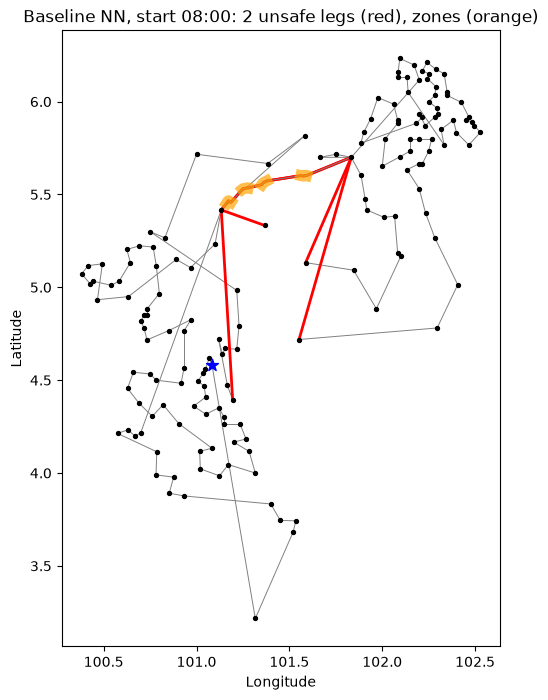

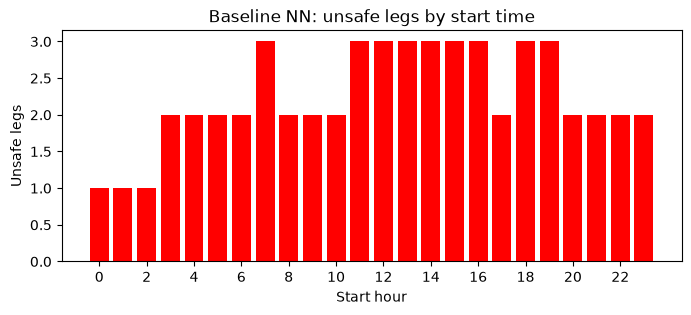

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
for l in result["legs"]:
    p = road_path(l["from"], l["to"], "R4" if l["route"] == "local" else l["route"])
    ax.plot([q[1] for q in p], [q[0] for q in p],
            color="red" if l["unsafe"] else "grey", lw=2 if l["unsafe"] else 0.7)
ax.scatter([t["lon"] for t in towns], [t["lat"] for t in towns], s=8, color="black", zorder=3)
for z in zones:
    ax.plot([p[1] for p in z["points"]], [p[0] for p in z["points"]], color="orange", lw=8, alpha=0.7)
ax.scatter([towns[start]["lon"]], [towns[start]["lat"]], s=80, marker="*", color="blue", zorder=4)
ax.set_title(f"Baseline NN, start {START_TIME}: {result['unsafe_legs']} unsafe legs (red), zones (orange)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")
os.makedirs(OUT_DIR, exist_ok=True)
plt.savefig(os.path.join(OUT_DIR, "baseline_map.png"), dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar([h for h, _, _ in by_hour], [u for _, u, _ in by_hour], color="red")
ax.set_xlabel("Start hour"); ax.set_ylabel("Unsafe legs"); ax.set_xticks(range(0, 24, 2))
ax.set_title("Baseline NN: unsafe legs by start time")
plt.savefig(os.path.join(OUT_DIR, "baseline_unsafe_by_hour.png"), dpi=150, bbox_inches="tight")
plt.show()

## 11. Save the output files

In [14]:
with open(os.path.join(OUT_DIR, "baseline_legs.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["leg", "from_id", "from", "to_id", "to", "route", "km", "wait_min",
                "depart", "arrive", "unsafe", "zones_hit"])
    for k, l in enumerate(result["legs"]):
        w.writerow([k, l["from"], towns[l["from"]]["name"], l["to"], towns[l["to"]]["name"], l["route"],
                    round(l["km"], 3), l["wait_min"], to_clock(l["depart"]), to_clock(l["arrive"]),
                    l["unsafe"], ";".join(l["zones_hit"])])

with open(os.path.join(OUT_DIR, "baseline_unsafe_by_hour.csv"), "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["start_hour", "unsafe_legs", "active_zones_driven_through"])
    w.writerows(by_hour)

lines = [
    f"Zones: {', '.join(z['id'] for z in zones)} from {ZONES_DIR}",
    f"Settings: start {START_TIME} at {START_TOWN}, speed {SPEED_KMH} km/h, sample every {SAMPLE_KM} km",
    f"Towns: {n}",
    f"Baseline NN: {result['total_km']:.1f} km, {result['total_min'] / 60:.1f} h, "
    f"{result['unsafe_legs']} unsafe legs, runtime {runtime_ms:.2f} ms",
    "Unsafe legs by start hour: " + ", ".join(f"{h:02d}h={u}" for h, u, _ in by_hour),
]
text = "\n".join(lines)
with open(os.path.join(OUT_DIR, "summary.txt"), "w") as f:
    f.write(text + "\n")
print(text)
print("Saved to", OUT_DIR)

Zones: Z1, Z2, Z3, Z4 from ..\data\zones(augmented data)
Settings: start 08:00 at Ipoh, speed 60 km/h, sample every 0.5 km
Towns: 161
Baseline NN: 4056.8 km, 67.6 h, 2 unsafe legs, runtime 2.75 ms
Unsafe legs by start hour: 00h=1, 01h=1, 02h=1, 03h=2, 04h=2, 05h=2, 06h=2, 07h=3, 08h=2, 09h=2, 10h=2, 11h=3, 12h=3, 13h=3, 14h=3, 15h=3, 16h=3, 17h=2, 18h=3, 19h=3, 20h=2, 21h=2, 22h=2, 23h=2
Saved to ..\02_baseline_simulator\output
